# **Indian Startup Funding Analysis**

## **`Project Overview`**

This project analyzes Indian startup funding data to understand funding patterns,
investment activity, startup sectors, cities, investors, and investment types.

The objective is to transform raw startup funding data into meaningful business
insights that can help understand where startup capital is being concentrated
and how funding activity has changed over time.

### **`Tools & Technologies`**

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

### **`Dataset`**

The dataset contains startup funding records including:

- Funding Date
- Startup Name
- Industry Vertical
- Sub-Vertical
- City
- Investors
- Investment Type
- Funding Amount
- Remarks

# **Business Questions**

This analysis aims to answer the following questions:

1. Which startup sectors received the highest total funding?
2. Which cities attracted the most startup funding?
3. Which investors participated in the highest number of funding deals?
4. How has startup funding changed over the years?
5. Which investment types received the most capital?
6. Which startups raised the largest funding amounts?
7. Which sectors have the highest average deal size?
8. How does the number of funding deals compare with total funding?
9. Which cities dominate particular startup sectors?
10. How concentrated is startup funding among large funding deals?

# **1. Importing Libraries:**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# **2. Load the Dataset:**

In [ ]:
df = pd.read_csv('/content/startup_funding.csv')

In [ ]:
df.head(10) # Starting 10 rows.

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN
5,6,13/01/2020,Pando,Logistics,"Open-market, freight management platform",Chennai,Chiratae Ventures,Series A,"90,00,000",NaN
6,7,10/01/2020,Zomato,Hospitality,Online Food Delivery Platform,Gurgaon,Ant Financial,Private Equity Round,"15,00,00,000",NaN
7,8,12/12/2019,Ecozen,Technology,Agritech,Pune,Sathguru Catalyzer Advisors,Series A,"60,00,000",NaN
8,9,06/12/2019,CarDekho,E-Commerce,Automobile,Gurgaon,Ping An Global Voyager Fund,Series D,"7,00,00,000",NaN
9,10,03/12/2019,Dhruva Space,Aerospace,Satellite Communication,Bengaluru,"Mumbai Angels, Ravikanth Reddy",Seed,"5,00,00,000",NaN


In [ ]:
df.shape # Check the shape of data.

(3044, 10)

# **3. Data Understanding:**

In [ ]:
df.info()  # see the data information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Sr No              3044 non-null   int64 
 1   Date dd/mm/yyyy    3044 non-null   object
 2   Startup Name       3044 non-null   object
 3   Industry Vertical  2873 non-null   object
 4   SubVertical        2108 non-null   object
 5   City  Location     2864 non-null   object
 6   Investors Name     3020 non-null   object
 7   InvestmentnType    3040 non-null   object
 8   Amount in USD      2084 non-null   object
 9   Remarks            419 non-null    object
dtypes: int64(1), object(9)
memory usage: 237.9+ KB


In [ ]:
df.describe(include="all").T  # see the statistical information.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Sr No,"3,044.00",NaN,NaN,NaN,"1,522.50",878.87,1.00,761.75,"1,522.50","2,283.25","3,044.00"
Date dd/mm/yyyy,3044,1035,30/11/2016,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Startup Name,3044,2459,Swiggy,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Industry Vertical,2873,821,Consumer Internet,941,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SubVertical,2108,1942,Online Lending Platform,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City Location,2864,112,Bangalore,700,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Investors Name,3020,2412,Undisclosed Investors,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InvestmentnType,3040,55,Private Equity,1356,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Amount in USD,2084,471,"10,00,000",165,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Remarks,419,72,Series A,175,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.columns  # see the column names.

Index(['Sr No', 'Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical',
       'SubVertical', 'City  Location', 'Investors Name', 'InvestmentnType',
       'Amount in USD', 'Remarks'],
      dtype='object')

# **4. Rename the Columns:**

In [ ]:
df = df.rename(columns={
    "Sr No": "Sr_No",
    "Date dd/mm/yyyy": "Date",
    "Startup Name": "Startup_Name",
    "Industry Vertical": "Industry_Vertical",
    "SubVertical": "Sub_Vertical",
    "City  Location": "City",
    "Investors Name": "Investors",
    "InvestmentnType": "Investment_Type",
    "Amount in USD": "Funding_USD",
    "Remarks": "Remarks"
})

df.columns

Index(['Sr_No', 'Date', 'Startup_Name', 'Industry_Vertical', 'Sub_Vertical',
       'City', 'Investors', 'Investment_Type', 'Funding_USD', 'Remarks'],
      dtype='object')

In [ ]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [ ]:
text_columns = [
    "Date",
    "Startup_Name",
    "Industry_Vertical",
    "Sub_Vertical",
    "City",
    "Investors",
    "Investment_Type",
    "Funding_USD",
    "Remarks"
]

for col in text_columns:

    df[col] = df[col].astype("string")

    df[col] = (
        df[col]
        .str.replace(r"\\+xc2\\+xa0", " ", regex=True)
        .str.replace("\xa0", " ", regex=False)
        .str.replace(r"\\n", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

In [ ]:
df.head(10)

,Sr_No,Date,Startup_Name,Industry_Vertical,Sub_Vertical,City,Investors,Investment_Type,Funding_USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",<NA>
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",<NA>
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",<NA>
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",<NA>
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",<NA>
5,6,13/01/2020,Pando,Logistics,"Open-market, freight management platform",Chennai,Chiratae Ventures,Series A,"90,00,000",<NA>
6,7,10/01/2020,Zomato,Hospitality,Online Food Delivery Platform,Gurgaon,Ant Financial,Private Equity Round,"15,00,00,000",<NA>
7,8,12/12/2019,Ecozen,Technology,Agritech,Pune,Sathguru Catalyzer Advisors,Series A,"60,00,000",<NA>
8,9,06/12/2019,CarDekho,E-Commerce,Automobile,Gurgaon,Ping An Global Voyager Fund,Series D,"7,00,00,000",<NA>
9,10,03/12/2019,Dhruva Space,Aerospace,Satellite Communication,Bengaluru,"Mumbai Angels, Ravikanth Reddy",Seed,"5,00,00,000",<NA>


# **5. Data Quality Assessment:**

In [ ]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})

missing_summary.sort_values(
    "Missing_Percentage",
    ascending=False
)

,Missing_Count,Missing_Percentage
Remarks,2625,86.24
Funding_USD,960,31.54
Sub_Vertical,936,30.75
City,180,5.91
Industry_Vertical,171,5.62
Investors,24,0.79
Investment_Type,4,0.13
Sr_No,0,0.00
Date,0,0.00
Startup_Name,0,0.00


In [ ]:
df["Date"] = pd.to_datetime(
    df["Date"],
    dayfirst=True,
    errors="coerce"
)

In [ ]:
print("Invalid dates:", df["Date"].isna().sum())

Invalid dates: 7


In [ ]:
df = df.dropna(subset=["Date"]).copy()

print("Rows after removing invalid dates:", len(df))

Rows after removing invalid dates: 3037


# **6. Funding Amount Cleaning:**

In [ ]:
df["Funding_USD"] = (
    df["Funding_USD"]
    .astype(str)
    .str.replace(",", "", regex=False)
)

df["Funding_USD"] = pd.to_numeric(
    df["Funding_USD"],
    errors="coerce"
)

In [ ]:
df["Funding_USD"].describe()

,Funding_USD
count,"2,066.00"
mean,"18,450,795.19"
std,"121,342,429.11"
min,"16,000.00"
25%,"477,750.00"
50%,"1,770,000.00"
75%,"8,036,295.50"
max,"3,900,000,000.00"


# **8. Missing Funding Amount:**

In [ ]:
print("Missing funding amounts:", df["Funding_USD"].isna().sum())

Missing funding amounts: 971


In [ ]:
funding_df = df.dropna(subset=["Funding_USD"]).copy()

print("Rows available for funding analysis:", len(funding_df))

Rows available for funding analysis: 2066


In [ ]:
df

,Sr_No,Date,Startup_Name,Industry_Vertical,Sub_Vertical,City,Investors,Investment_Type,Funding_USD,Remarks
0,1,2020-01-09,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"200,000,000.00",<NA>
1,2,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"8,048,394.00",<NA>
2,3,2020-01-09,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"18,358,860.00",<NA>
3,4,2020-01-02,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"3,000,000.00",<NA>
4,5,2020-01-02,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"1,800,000.00",<NA>
...,...,...,...,...,...,...,...,...,...,...
3039,3040,2015-01-29,Printvenue,<NA>,<NA>,<NA>,Asia Pacific Internet Group,Private Equity,"4,500,000.00",<NA>
3040,3041,2015-01-29,Graphene,<NA>,<NA>,<NA>,KARSEMVEN Fund,Private Equity,"825,000.00",Govt backed VC Fund
3041,3042,2015-01-30,Mad Street Den,<NA>,<NA>,<NA>,"Exfinity Fund, GrowX Ventures.",Private Equity,"1,500,000.00",<NA>
3042,3043,2015-01-30,Simplotel,<NA>,<NA>,<NA>,MakeMyTrip,Private Equity,NaN,"Strategic Funding, Minority stake"


In [ ]:
funding_df

,Sr_No,Date,Startup_Name,Industry_Vertical,Sub_Vertical,City,Investors,Investment_Type,Funding_USD,Remarks
0,1,2020-01-09,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"200,000,000.00",<NA>
1,2,2020-01-13,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"8,048,394.00",<NA>
2,3,2020-01-09,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"18,358,860.00",<NA>
3,4,2020-01-02,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"3,000,000.00",<NA>
4,5,2020-01-02,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"1,800,000.00",<NA>
...,...,...,...,...,...,...,...,...,...,...
3038,3039,2015-01-28,Grabhouse.com,<NA>,<NA>,<NA>,"Kalaari Capital, Sequoia Capital",Private Equity,"2,500,000.00",Series A
3039,3040,2015-01-29,Printvenue,<NA>,<NA>,<NA>,Asia Pacific Internet Group,Private Equity,"4,500,000.00",<NA>
3040,3041,2015-01-29,Graphene,<NA>,<NA>,<NA>,KARSEMVEN Fund,Private Equity,"825,000.00",Govt backed VC Fund
3041,3042,2015-01-30,Mad Street Den,<NA>,<NA>,<NA>,"Exfinity Fund, GrowX Ventures.",Private Equity,"1,500,000.00",<NA>


# **9. Text Columns Cleaning:**

In [ ]:
text_columns = [
    "Startup_Name",
    "Industry_Vertical",
    "Sub_Vertical",
    "City",
    "Investors",
    "Investment_Type",
    "Remarks"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# **10. Missing Text Values:**

In [ ]:
text_columns = [
    "Industry_Vertical",
    "Sub_Vertical",
    "City",
    "Investors"
]

for col in text_columns:
    df[col] = df[col].fillna("Unknown")

In [ ]:
df["Remarks"] = df["Remarks"].fillna("No Remarks")

In [ ]:
df["Investment_Type"] = df["Investment_Type"].fillna("Unknown")

# **11. Clean Industry Names:**

In [ ]:
df["Industry_Vertical"] = (
    df["Industry_Vertical"]
    .str.strip()
    .str.lower()
)

In [ ]:
industry_mapping = {
    "ecommerce": "e-commerce",
    "e-commerce": "e-commerce",
    "e commerce": "e-commerce",
    "technology": "tech",
    "tech": "tech",
    "fintech": "fintech"
}

df["Industry_Vertical"] = df["Industry_Vertical"].replace(industry_mapping)

In [ ]:
df["Industry_Vertical"].value_counts().head(20)

,count
Industry_Vertical,
consumer internet,941
tech,480
e-commerce,299
unknown,169
healthcare,71
finance,62
logistics,32
education,24
food & beverage,23


# **12. Investment Type Cleaning:**

In [ ]:
df["Investment_Type"] = (
    df["Investment_Type"]
    .str.lower()
    .str.replace(r"\\n", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

In [ ]:
investment_mapping = {
    "seed": "seed round",
    "seed funding": "seed round",
    "seed funding round": "seed round",
    "seed/ angel funding": "seed round",
    "seed / angel funding": "seed round",
    "seed/angel funding": "seed round",
    "seed / angle funding": "seed round",
    "angel / seed funding": "seed round",
    "angel funding": "angel round",
    "angel": "angel round",

    "pre-series a": "pre-series a",
    "pre-series a ": "pre-series a",
    "pre series a": "pre-series a",

    "venture": "venture round",
    "single venture": "venture round",
    "venture - series unknown": "venture round",

    "private": "private equity round",
    "private equity": "private equity round",
    "privateequity": "private equity round",
    "private funding": "private equity round",

    "debt": "debt funding",
    "debt-funding": "debt funding",
    "debt and preference capital": "debt funding",
    "structured debt": "debt funding",
    "term loan": "debt funding",
    "mezzanine": "debt funding",

    "equity based funding": "equity"
}

df["Investment_Type"] = df["Investment_Type"].replace(investment_mapping)

In [ ]:
df["Investment_Type"].value_counts().head(20)

,count
Investment_Type,
seed round,1503
private equity round,1362
debt funding,31
seed\ funding,30
series a,24
series b,20
series c,14
series d,12
pre-series a,9


# **13. Feature Engineering:**

In [ ]:
# Create date-based features

df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Quarter"] = df["Date"].dt.quarter
df["Year_Month"] = df["Date"].dt.to_period("M").astype(str)

In [ ]:
# Create dataset for funding-related analysis

funding_df = df.dropna(subset=["Funding_USD"]).copy()

In [ ]:
print(df.columns.tolist())
print(funding_df.columns.tolist())

['Sr_No', 'Date', 'Startup_Name', 'Industry_Vertical', 'Sub_Vertical', 'City', 'Investors', 'Investment_Type', 'Funding_USD', 'Remarks', 'Year', 'Month', 'Month_Name', 'Quarter', 'Year_Month']
['Sr_No', 'Date', 'Startup_Name', 'Industry_Vertical', 'Sub_Vertical', 'City', 'Investors', 'Investment_Type', 'Funding_USD', 'Remarks', 'Year', 'Month', 'Month_Name', 'Quarter', 'Year_Month']


In [ ]:
funding_df["Year"] = funding_df["Date"].dt.year
funding_df["Month"] = funding_df["Date"].dt.month
funding_df["Month_Name"] = funding_df["Date"].dt.month_name()
funding_df["Quarter"] = funding_df["Date"].dt.quarter

In [ ]:
funding_df.head()

,Sr_No,Date,Startup_Name,Industry_Vertical,Sub_Vertical,City,Investors,Investment_Type,Funding_USD,Remarks,Year,Month,Month_Name,Quarter,Year_Month
0,1,2020-01-09,BYJU’S,e-tech,E-learning,Bengaluru,Tiger Global Management,private equity round,"200,000,000.00",No Remarks,2020,1,January,1,2020-01
1,2,2020-01-13,Shuttl,transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,series c,"8,048,394.00",No Remarks,2020,1,January,1,2020-01
2,3,2020-01-09,Mamaearth,e-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,series b,"18,358,860.00",No Remarks,2020,1,January,1,2020-01
3,4,2020-01-02,https://www.wealthbucket.in/,fintech,Online Investment,New Delhi,Vinod Khatumal,pre-series a,"3,000,000.00",No Remarks,2020,1,January,1,2020-01
4,5,2020-01-02,Fashor,fashion and apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,seed round,"1,800,000.00",No Remarks,2020,1,January,1,2020-01


In [ ]:
df['City'].unique()

<StringArray>
[             'Bengaluru',                'Gurgaon',              'New Delhi',
                 'Mumbai',                'Chennai',                   'Pune',
                  'Noida',              'Faridabad',          'San Francisco',
              'San Jose,',
 ...
  'Bangalore / San Mateo',        'New York/ India',               'US/India',
          'Gurgaon / SFO',        'Bangalore / USA',     'New Delhi/ Houston',
        'Mumbai / Global',             'India / US', 'New Delhi / California',
     'Dallas / Hyderabad']
Length: 108, dtype: string

### **Clean City Names**

In [ ]:
# Clean City column without changing its name

df["City"] = (
    df["City"]
    .astype("string")

    # Remove non-breaking spaces / encoding artifacts
    .str.replace("\xa0", " ", regex=False)
    .str.replace(r"\\xC2\\xA0", " ", regex=True)
    .str.replace(r"\\xc2\\xa0", " ", regex=True)

    # Remove extra spaces
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()

    # Remove trailing commas
    .str.replace(r",+$", "", regex=True)
    .str.strip()
)

In [ ]:
city_mapping = {
    "Bangalore": "Bengaluru",
    "Gurgaon": "Gurugram",
    "Delhi": "New Delhi"
}

df["City"] = df["City"].replace(city_mapping)

In [ ]:
df.loc[
    df["City"].str.contains("/", na=False),
    "City"
] = "Multiple Locations"

In [ ]:
df["City"] = df["City"].fillna("Unknown")

df.loc[
    df["City"].str.strip().eq(""),
    "City"
] = "Unknown"

In [ ]:
df["City"].value_counts().head(30)

,count
City,
Bengaluru,842
Mumbai,564
New Delhi,458
Gurugram,341
Unknown,178
Pune,105
Hyderabad,99
Chennai,97
Noida,93


In [ ]:
df[df["City"].str.contains(
    r"xc2|/|,",
    case=False,
    na=False
)][["City"]].head(50)

,City
131,"New York, Bengaluru"


In [ ]:
funding_df = df.dropna(subset=["Funding_USD"]).copy()

# **14. Final Data Quality Check**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3037 entries, 0 to 3043
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Sr_No              3037 non-null   int64         
 1   Date               3037 non-null   datetime64[ns]
 2   Startup_Name       3037 non-null   string        
 3   Industry_Vertical  3037 non-null   string        
 4   Sub_Vertical       3037 non-null   string        
 5   City               3037 non-null   string        
 6   Investors          3037 non-null   string        
 7   Investment_Type    3037 non-null   string        
 8   Funding_USD        2066 non-null   float64       
 9   Remarks            3037 non-null   string        
 10  Year               3037 non-null   int32         
 11  Month              3037 non-null   int32         
 12  Month_Name         3037 non-null   object        
 13  Quarter            3037 non-null   int32         
 14  Year_Month   

In [ ]:
df.isna().sum()

,0
Sr_No,0
Date,0
Startup_Name,0
Industry_Vertical,0
Sub_Vertical,0
City,0
Investors,0
Investment_Type,0
Funding_USD,971
Remarks,0


# **15. KPI Analysis:**

The following KPIs provide a high-level overview of startup funding activity.

In [ ]:
total_deals = len(df)

total_startups = df["Startup_Name"].nunique()

total_funding = funding_df["Funding_USD"].sum()

average_funding = funding_df["Funding_USD"].mean()

median_funding = funding_df["Funding_USD"].median()

max_funding = funding_df["Funding_USD"].max()

total_cities = df["City"].nunique()

total_industries = df["Industry_Vertical"].nunique()

total_investors = df["Investors"].nunique()

print(f"Total Funding Deals      : {total_deals:,}")
print(f"Unique Startups          : {total_startups:,}")
print(f"Total Funding            : ${total_funding:,.0f}")
print(f"Average Funding          : ${average_funding:,.0f}")
print(f"Median Funding           : ${median_funding:,.0f}")
print(f"Largest Funding          : ${max_funding:,.0f}")
print(f"Unique Cities            : {total_cities:,}")
print(f"Unique Industries        : {total_industries:,}")
print(f"Unique Investor Entries  : {total_investors:,}")

Total Funding Deals      : 3,037
Unique Startups          : 2,452
Total Funding            : $38,119,342,864
Average Funding          : $18,450,795
Median Funding           : $1,770,000
Largest Funding          : $3,900,000,000
Unique Cities            : 76
Unique Industries        : 797
Unique Investor Entries  : 2,404


# **16. KPI DataFrame:**

In [ ]:
kpi_df = pd.DataFrame({
    "Metric": [
        "Total Deals",
        "Unique Startups",
        "Total Funding",
        "Average Funding",
        "Median Funding",
        "Largest Funding",
        "Unique Cities",
        "Unique Industries"
    ],

    "Value": [
        total_deals,
        total_startups,
        total_funding,
        average_funding,
        median_funding,
        max_funding,
        total_cities,
        total_industries
    ]
})

kpi_df

,Metric,Value
0,Total Deals,"3,037.00"
1,Unique Startups,"2,452.00"
2,Total Funding,"38,119,342,864.22"
3,Average Funding,"18,450,795.19"
4,Median Funding,"1,770,000.00"
5,Largest Funding,"3,900,000,000.00"
6,Unique Cities,76.00
7,Unique Industries,797.00


# **17. Year-wise Funding Trend:**


In [ ]:
yearly_analysis = (
    funding_df
    .groupby("Year")
    .agg(
        Total_Funding=("Funding_USD", "sum"),
        Number_of_Deals=("Funding_USD", "count"),
        Average_Deal=("Funding_USD", "mean"),
        Median_Deal=("Funding_USD", "median")
    )
    .reset_index()
)

yearly_analysis

,Year,Total_Funding,Number_of_Deals,Average_Deal,Median_Deal
0,2015,"8,669,042,368.00",649,"13,357,538.32","1,500,000.00"
1,2016,"3,828,088,608.00",586,"6,532,574.42","1,000,000.00"
2,2017,"10,429,309,730.00",456,"22,871,293.27","2,250,000.00"
3,2018,"5,116,118,369.00",264,"19,379,236.25","3,900,000.00"
4,2019,"9,686,576,535.22",104,"93,140,158.99","12,000,000.00"
5,2020,"390,207,254.00",7,"55,743,893.43","9,000,000.00"


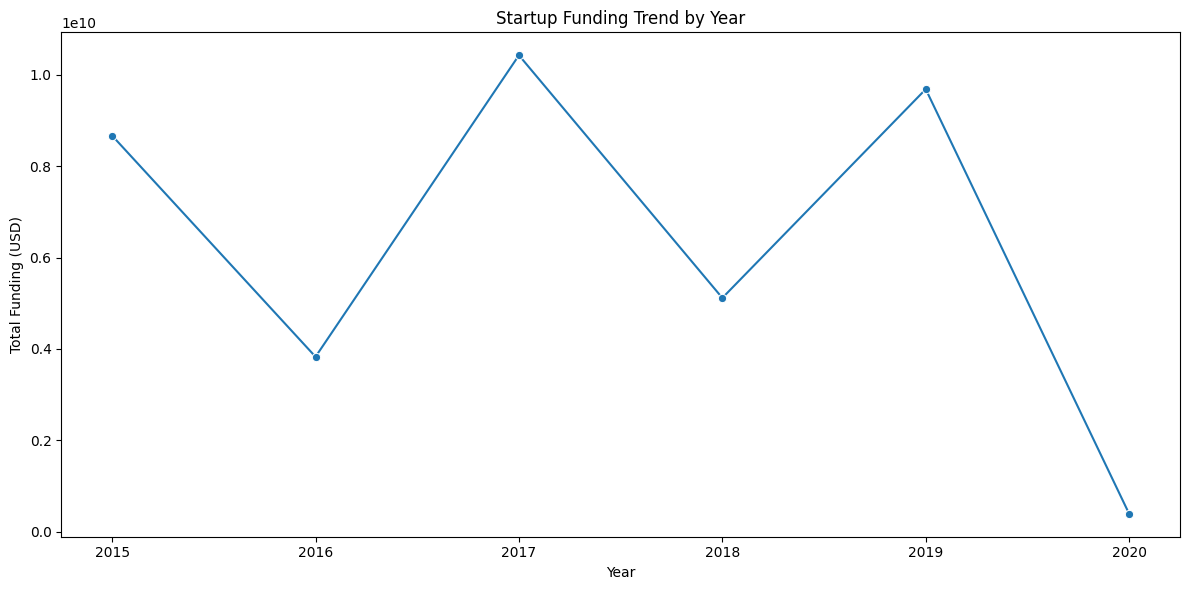

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_analysis,
    x="Year",
    y="Total_Funding",
    marker="o"
)

plt.title("Startup Funding Trend by Year")
plt.xlabel("Year")
plt.ylabel("Total Funding (USD)")
plt.xticks(yearly_analysis["Year"])
plt.tight_layout()
plt.show()

# **18. Number of Deals Over Time:**

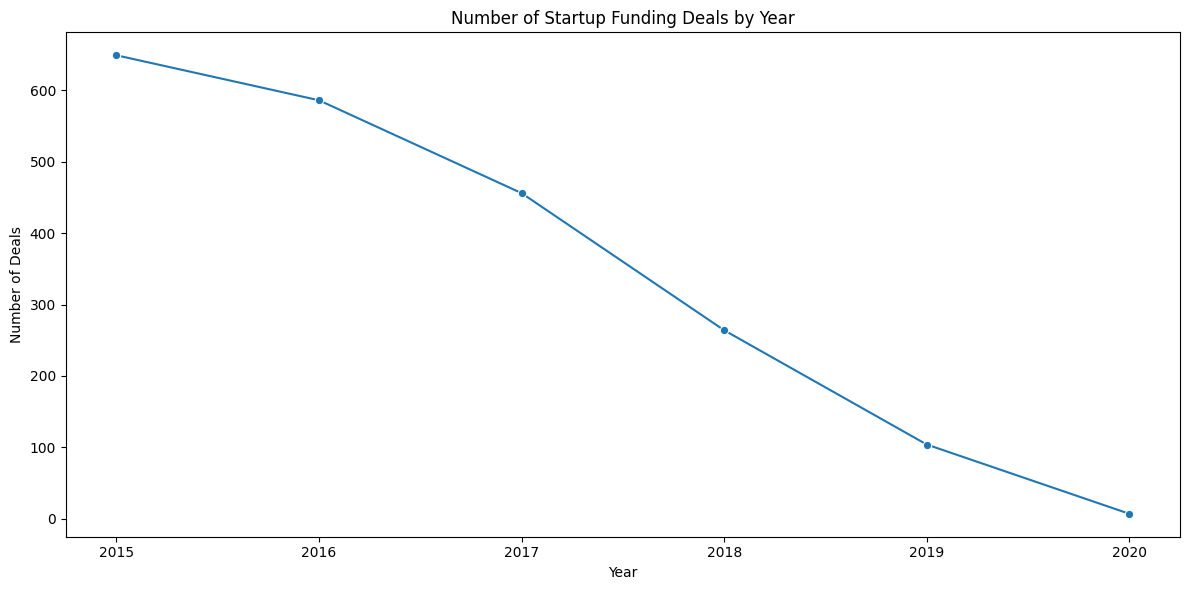

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_analysis,
    x="Year",
    y="Number_of_Deals",
    marker="o"
)

plt.title("Number of Startup Funding Deals by Year")
plt.xlabel("Year")
plt.ylabel("Number of Deals")
plt.xticks(yearly_analysis["Year"])
plt.tight_layout()
plt.show()

# **19. Average Deal Size:**

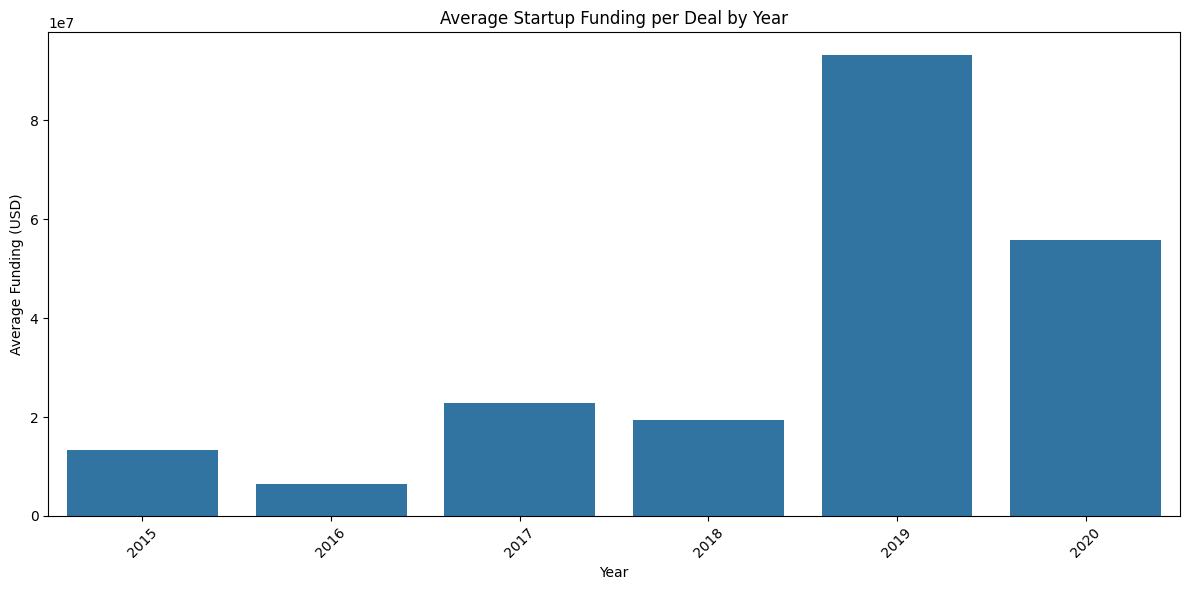

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=yearly_analysis,
    x="Year",
    y="Average_Deal"
)

plt.title("Average Startup Funding per Deal by Year")
plt.xlabel("Year")
plt.ylabel("Average Funding (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **20. Top Funded Sectors:**

In [ ]:
sector_analysis = (
    funding_df
    .groupby("Industry_Vertical")
    .agg(
        Total_Funding=("Funding_USD", "sum"),
        Number_of_Deals=("Funding_USD", "count"),
        Average_Funding=("Funding_USD", "mean"),
        Median_Funding=("Funding_USD", "median")
    )
    .sort_values("Total_Funding", ascending=False)
)

sector_analysis.head(15)

,Total_Funding,Number_of_Deals,Average_Funding,Median_Funding
Industry_Vertical,,,,
e-commerce,"8,246,393,692.54",204,"40,423,498.49","3,000,000.00"
consumer internet,"6,247,834,245.00",589,"10,607,528.43","1,000,000.00"
transportation,"3,916,632,394.00",4,"979,158,098.50","6,524,197.00"
tech,"2,251,457,930.00",312,"7,216,211.31","1,500,000.00"
finance,"1,971,438,000.00",57,"34,586,631.58","6,240,000.00"
unknown,"1,230,961,368.00",129,"9,542,336.19","1,500,000.00"
fintech,"1,224,211,265.00",10,"122,421,126.50","15,250,000.00"
online marketplace,"700,143,000.00",2,"350,071,500.00","350,071,500.00"
e-commerce & m-commerce platform,"680,000,000.00",1,"680,000,000.00","680,000,000.00"


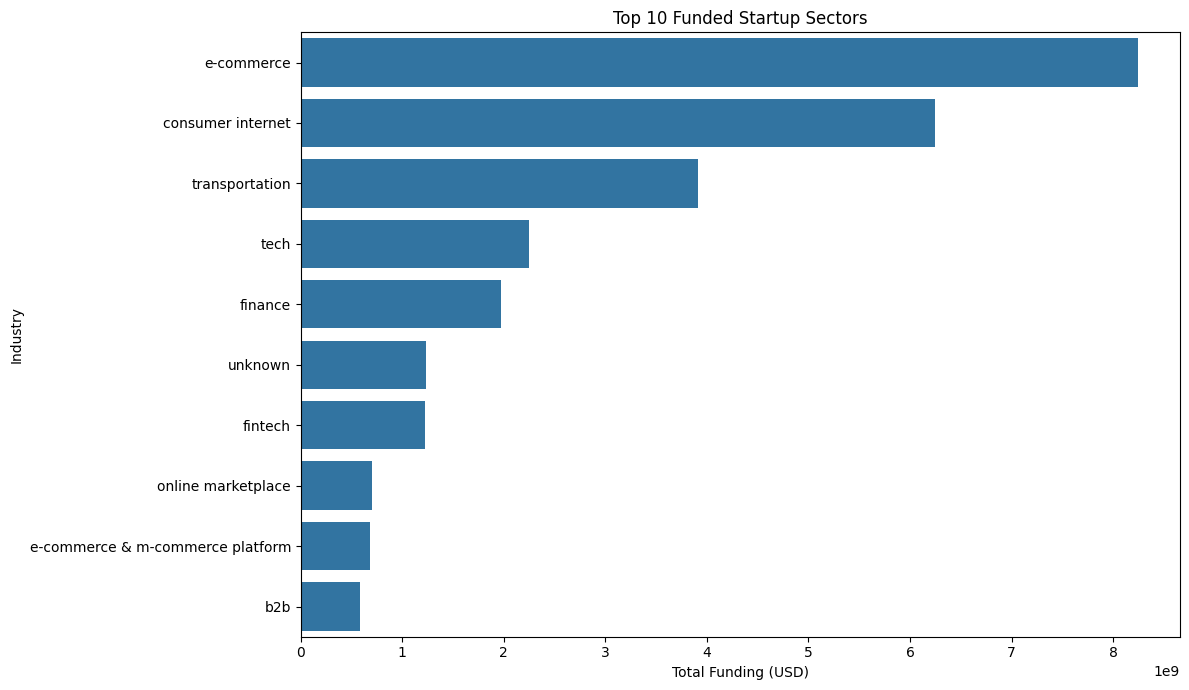

In [ ]:
top_sectors = (
    sector_analysis
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_sectors,
    x="Total_Funding",
    y="Industry_Vertical"
)

plt.title("Top 10 Funded Startup Sectors")
plt.xlabel("Total Funding (USD)")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

# **21. Number of Deals by Sector:**

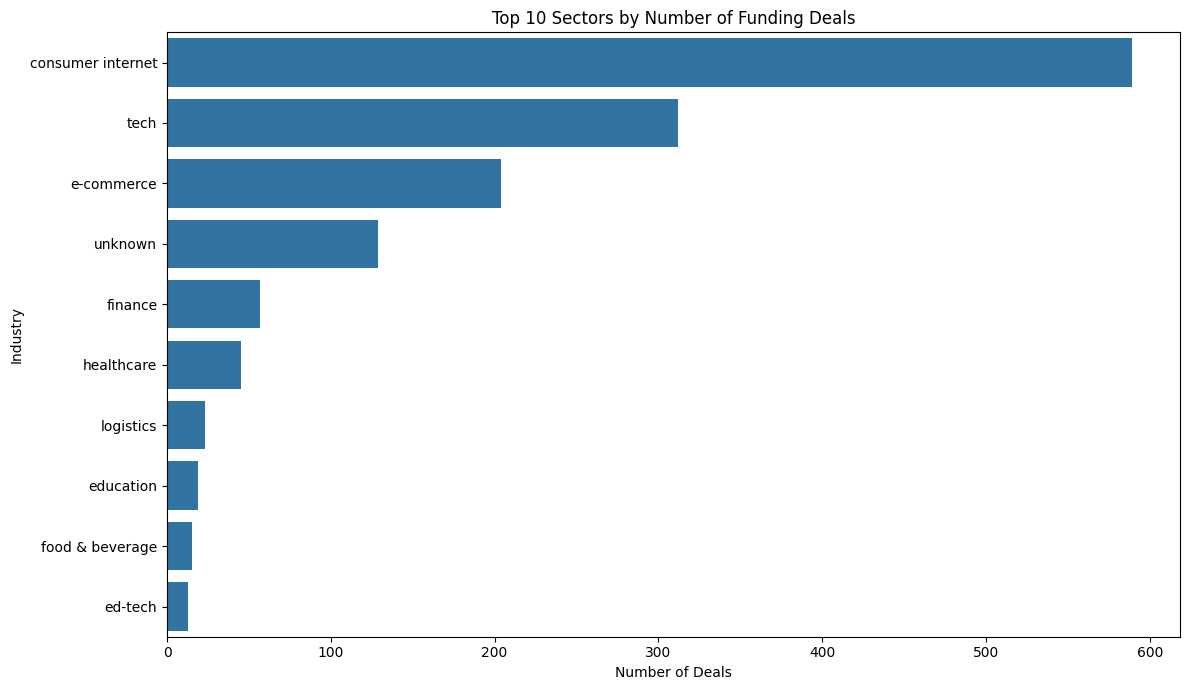

In [ ]:
top_sector_deals = (
    sector_analysis
    .sort_values("Number_of_Deals", ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_sector_deals,
    x="Number_of_Deals",
    y="Industry_Vertical"
)

plt.title("Top 10 Sectors by Number of Funding Deals")
plt.xlabel("Number of Deals")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

# **22. Average Funding by Sector:**

In [ ]:
sector_avg = (
    sector_analysis[
        sector_analysis["Number_of_Deals"] >= 5
    ]
    .sort_values("Average_Funding", ascending=False)
    .head(10)
    .reset_index()
)

sector_avg

,Industry_Vertical,Total_Funding,Number_of_Deals,Average_Funding,Median_Funding
0,fintech,"1,224,211,265.00",10,"122,421,126.50","15,250,000.00"
1,health and wellness,"490,686,000.00",6,"81,781,000.00","9,000,000.00"
2,e-commerce,"8,246,393,692.54",204,"40,423,498.49","3,000,000.00"
3,finance,"1,971,438,000.00",57,"34,586,631.58","6,240,000.00"
4,edtech,"157,947,425.00",5,"31,589,485.00","1,000,000.00"
5,online food delivery,"121,500,000.00",5,"24,300,000.00","3,500,000.00"
6,fin-tech,"140,700,000.00",6,"23,450,000.00","4,600,000.00"
7,education,"301,143,000.00",19,"15,849,631.58","1,500,000.00"
8,consumer internet,"6,247,834,245.00",589,"10,607,528.43","1,000,000.00"
9,logistics,"242,845,000.00",23,"10,558,478.26","6,000,000.00"


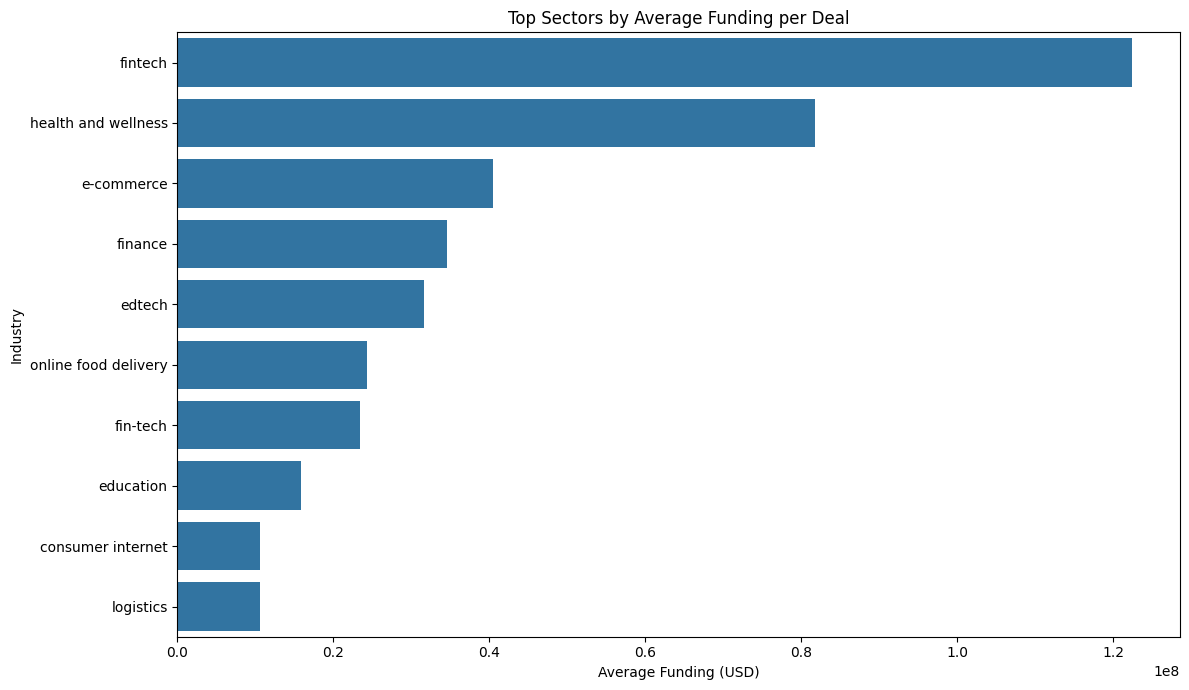

In [ ]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=sector_avg,
    x="Average_Funding",
    y="Industry_Vertical"
)

plt.title("Top Sectors by Average Funding per Deal")
plt.xlabel("Average Funding (USD)")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

# **23. City-wise Funding:** **bold text**

In [ ]:
city_analysis = (
    funding_df
    .groupby("City")
    .agg(
        Total_Funding=("Funding_USD", "sum"),
        Number_of_Deals=("Funding_USD", "count"),
        Average_Funding=("Funding_USD", "mean")
    )
    .sort_values("Total_Funding", ascending=False)
)

city_analysis.head(15)

,Total_Funding,Number_of_Deals,Average_Funding
City,,,
Bengaluru,"18,476,366,863.00",583,"31,691,881.41"
Mumbai,"4,931,155,015.00",398,"12,389,836.72"
Gurugram,"3,876,913,657.54",243,"15,954,377.19"
New Delhi,"3,302,171,515.00",268,"12,321,535.50"
Noida,"1,282,864,000.00",56,"22,908,285.71"
Unknown,"1,271,013,868.00",133,"9,556,495.25"
Chennai,"718,767,000.00",75,"9,583,560.00"
Pune,"633,082,000.00",71,"8,916,647.89"
Multiple Locations,"544,590,000.00",32,"17,018,437.50"


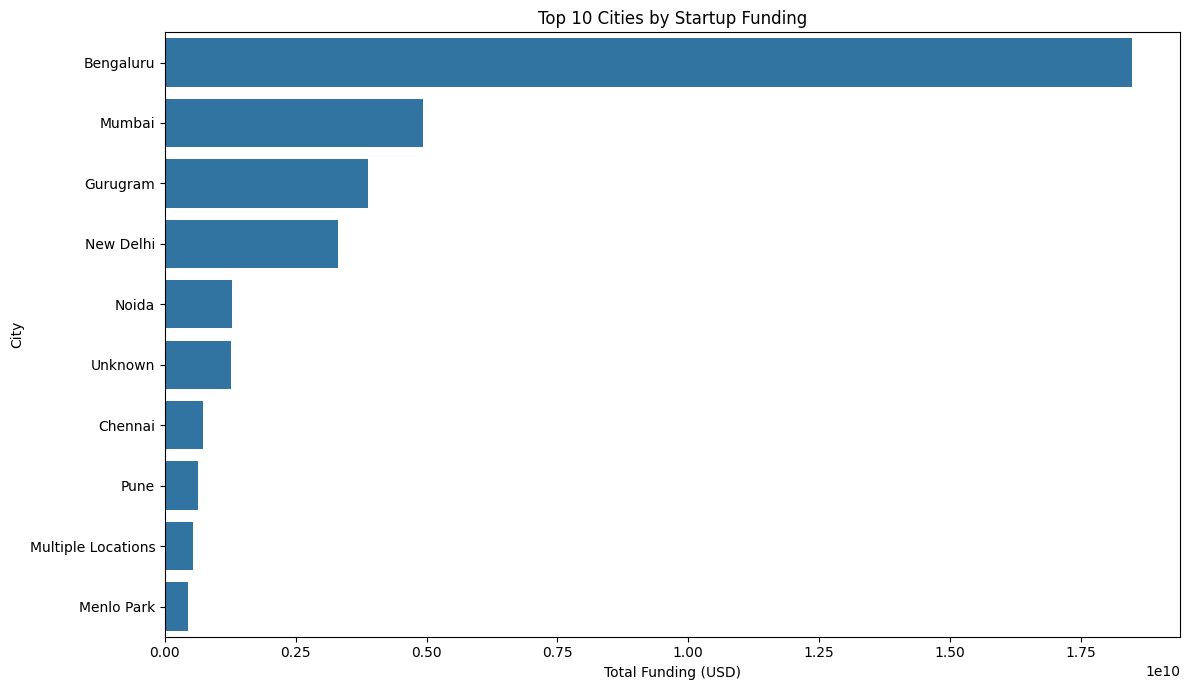

In [ ]:
top_cities = city_analysis.head(10).reset_index()

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_cities,
    x="Total_Funding",
    y="City"
)

plt.title("Top 10 Cities by Startup Funding")
plt.xlabel("Total Funding (USD)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

# **24. City by Number of Deals:**

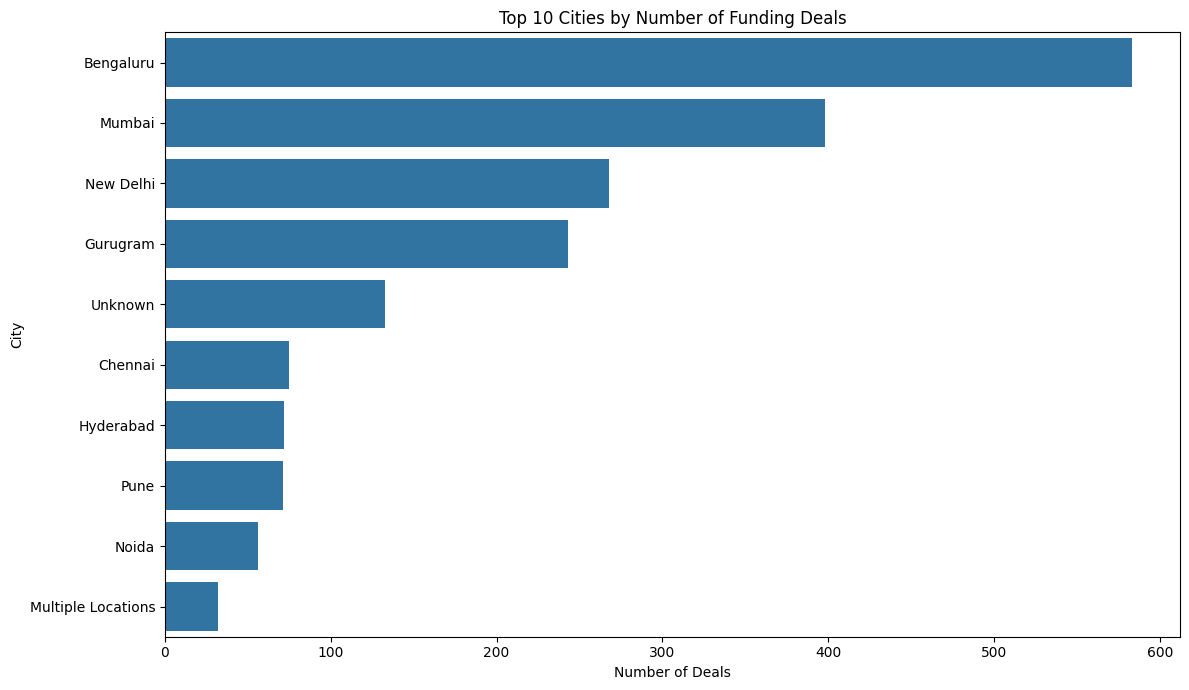

In [ ]:
city_deals = (
    city_analysis
    .sort_values("Number_of_Deals", ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=city_deals,
    x="Number_of_Deals",
    y="City"
)

plt.title("Top 10 Cities by Number of Funding Deals")
plt.xlabel("Number of Deals")
plt.ylabel("City")
plt.tight_layout()
plt.show()

# **25. Investment Type Analysis:**

In [ ]:
investment_analysis = (
    funding_df
    .groupby("Investment_Type")
    .agg(
        Total_Funding=("Funding_USD", "sum"),
        Number_of_Deals=("Funding_USD", "count"),
        Average_Funding=("Funding_USD", "mean"),
        Median_Funding=("Funding_USD", "median")
    )
    .sort_values("Total_Funding", ascending=False)
)

investment_analysis.head(15)

,Total_Funding,Number_of_Deals,Average_Funding,Median_Funding
Investment_Type,,,,
private equity round,"27,257,998,165.00",1077,"25,309,190.50","6,000,000.00"
series b,"4,799,195,735.00",20,"239,959,786.75","15,900,000.00"
series d,"1,481,799,000.00",12,"123,483,250.00","65,000,000.00"
series c,"1,044,718,394.00",14,"74,622,742.43","50,000,000.00"
seed round,"1,041,829,318.00",835,"1,247,699.78","375,000.00"
funding round,"1,000,000,000.00",1,"1,000,000,000.00","1,000,000,000.00"
series g,"231,000,000.00",1,"231,000,000.00","231,000,000.00"
unknown,"207,629,010.22",3,"69,209,670.07","4,889,975.54"
series a,"203,200,000.00",22,"9,236,363.64","4,250,000.00"


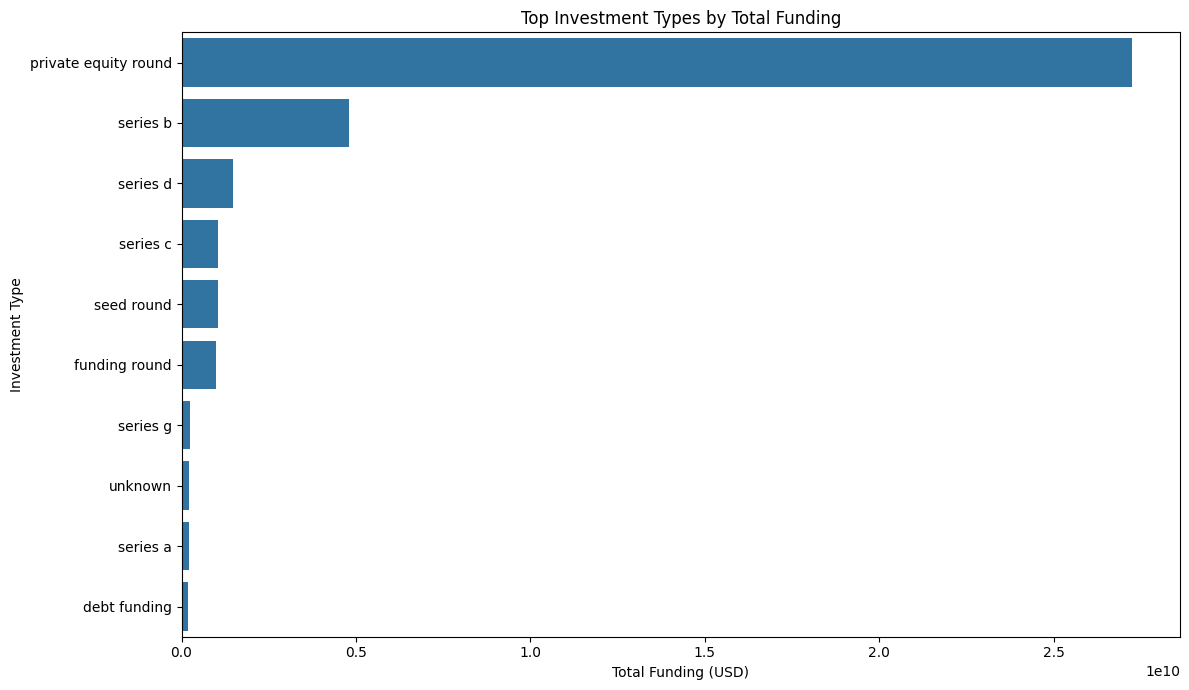

In [ ]:
top_investment_types = (
    investment_analysis
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_investment_types,
    x="Total_Funding",
    y="Investment_Type"
)

plt.title("Top Investment Types by Total Funding")
plt.xlabel("Total Funding (USD)")
plt.ylabel("Investment Type")
plt.tight_layout()
plt.show()

# **26. Investment Type by Deal Count:**

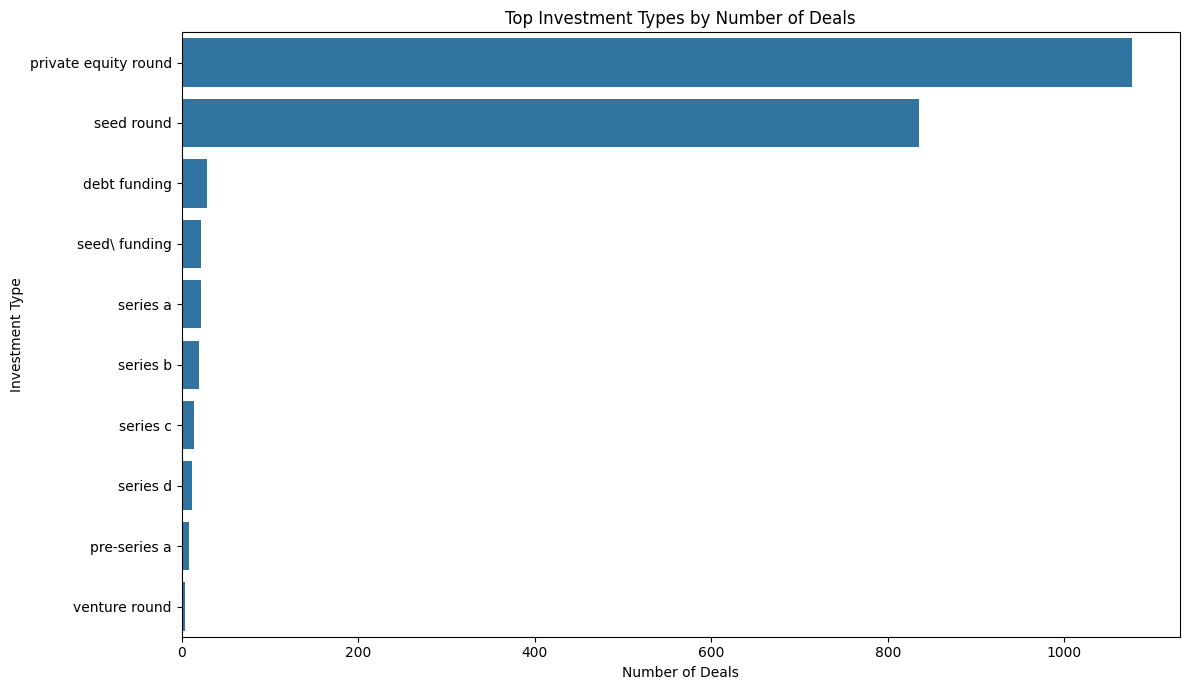

In [ ]:
investment_deals = (
    investment_analysis
    .sort_values("Number_of_Deals", ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=investment_deals,
    x="Number_of_Deals",
    y="Investment_Type"
)

plt.title("Top Investment Types by Number of Deals")
plt.xlabel("Number of Deals")
plt.ylabel("Investment Type")
plt.tight_layout()
plt.show()

# **27. Top Funded Startups:**

In [ ]:
startup_analysis = (
    funding_df
    .groupby("Startup_Name")
    .agg(
        Total_Funding=("Funding_USD", "sum"),
        Number_of_Deals=("Funding_USD", "count"),
        Average_Funding=("Funding_USD", "mean")
    )
    .sort_values("Total_Funding", ascending=False)
)

startup_analysis.head(15)

,Total_Funding,Number_of_Deals,Average_Funding
Startup_Name,,,
Flipkart,"4,059,700,000.00",5,"811,940,000.00"
Rapido Bike Taxi,"3,900,000,000.00",1,"3,900,000,000.00"
Paytm,"3,148,950,000.00",5,"629,790,000.00"
Ola,"984,500,000.00",4,"246,125,000.00"
Udaan,"870,000,000.00",4,"217,500,000.00"
Snapdeal,"700,000,000.00",2,"350,000,000.00"
Flipkart.com,"700,000,000.00",1,"700,000,000.00"
Ola Cabs,"669,700,000.00",7,"95,671,428.57"
True North,"600,000,000.00",1,"600,000,000.00"


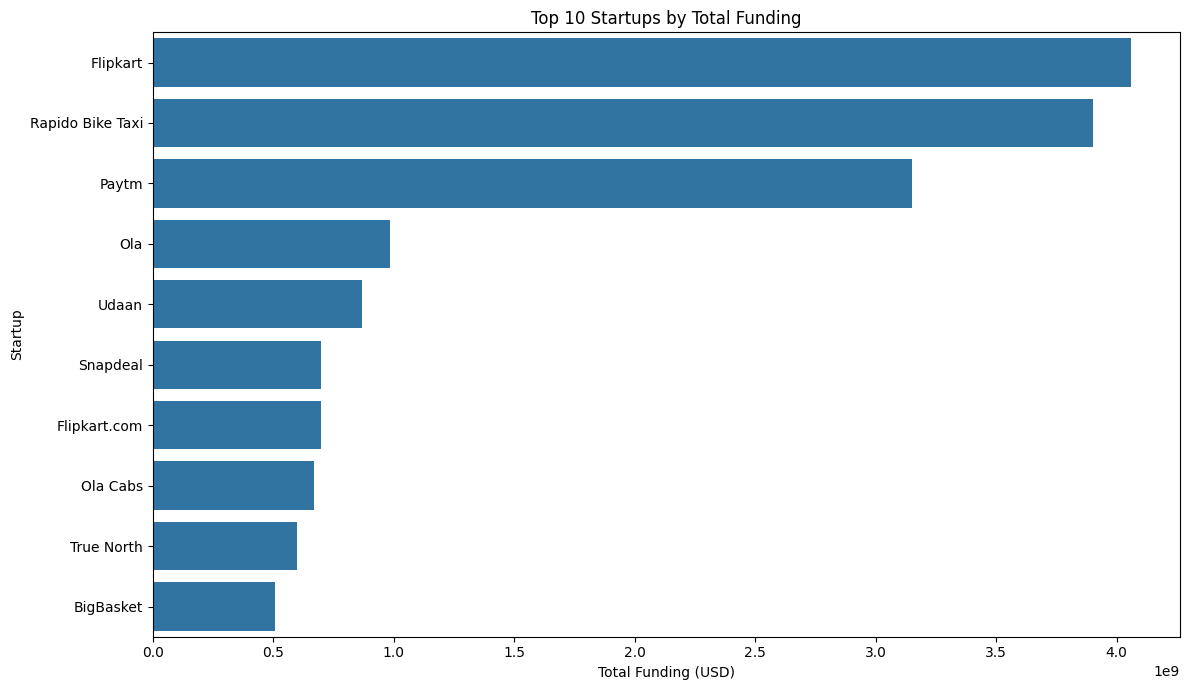

In [ ]:
top_startups = (
    startup_analysis
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_startups,
    x="Total_Funding",
    y="Startup_Name"
)

plt.title("Top 10 Startups by Total Funding")
plt.xlabel("Total Funding (USD)")
plt.ylabel("Startup")
plt.tight_layout()
plt.show()

# **28. Largest Individual Funding Deals:**

In [ ]:
largest_deals = (
    funding_df[
        [
            "Date",
            "Startup_Name",
            "Industry_Vertical",
            "City",
            "Investment_Type",
            "Funding_USD"
        ]
    ]
    .sort_values("Funding_USD", ascending=False)
    .head(20)
)

largest_deals

,Date,Startup_Name,Industry_Vertical,City,Investment_Type,Funding_USD
60,2019-08-27,Rapido Bike Taxi,transportation,Bengaluru,series b,"3,900,000,000.00"
651,2017-08-11,Flipkart,e-commerce,Bengaluru,private equity round,"2,500,000,000.00"
830,2017-05-18,Paytm,e-commerce,Bengaluru,private equity round,"1,400,000,000.00"
966,2017-03-21,Flipkart,e-commerce,Bengaluru,private equity round,"1,400,000,000.00"
31,2019-11-25,Paytm,fintech,Noida,funding round,"1,000,000,000.00"
2648,2015-07-28,Flipkart.com,online marketplace,Bengaluru,private equity round,"700,000,000.00"
2459,2015-09-29,Paytm,e-commerce & m-commerce platform,New Delhi,private equity round,"680,000,000.00"
188,2018-08-30,True North,finance,Mumbai,private equity round,"600,000,000.00"
33,2019-10-02,Udaan,b2b,Bengaluru,series d,"585,000,000.00"
2470,2015-08-01,Snapdeal,ecommerce marketplace,New Delhi,private equity round,"500,000,000.00"


# **29. Top Investors:**

In [ ]:
investor_df = funding_df.copy()

investor_df["Investors"] = (
    investor_df["Investors"]
    .fillna("Unknown")
    .astype(str)
    .str.split(",")
)

investor_df = investor_df.explode("Investors")

investor_df["Investors"] = (
    investor_df["Investors"]
    .str.strip()
)

In [ ]:
investor_analysis = (
    investor_df[
        investor_df["Investors"].ne("Unknown")
    ]
    .groupby("Investors")
    .agg(
        Deal_Count=("Startup_Name", "count"),
        Associated_Funding=("Funding_USD", "sum")
    )
    .sort_values("Deal_Count", ascending=False)
)

investor_analysis.head(20)

,Deal_Count,Associated_Funding
Investors,,
Sequoia Capital,68,"1,656,630,000.00"
Accel Partners,60,"891,680,000.00"
SAIF Partners,48,"606,550,000.00"
Kalaari Capital,47,"617,370,000.00"
,36,"354,753,665.00"
Blume Ventures,35,"172,762,000.00"
Undisclosed Investors,29,"32,106,000.00"
Tiger Global,28,"2,065,400,000.00"
Nexus Venture Partners,27,"457,730,200.00"


# **30. Top Investors by Deal Count:**

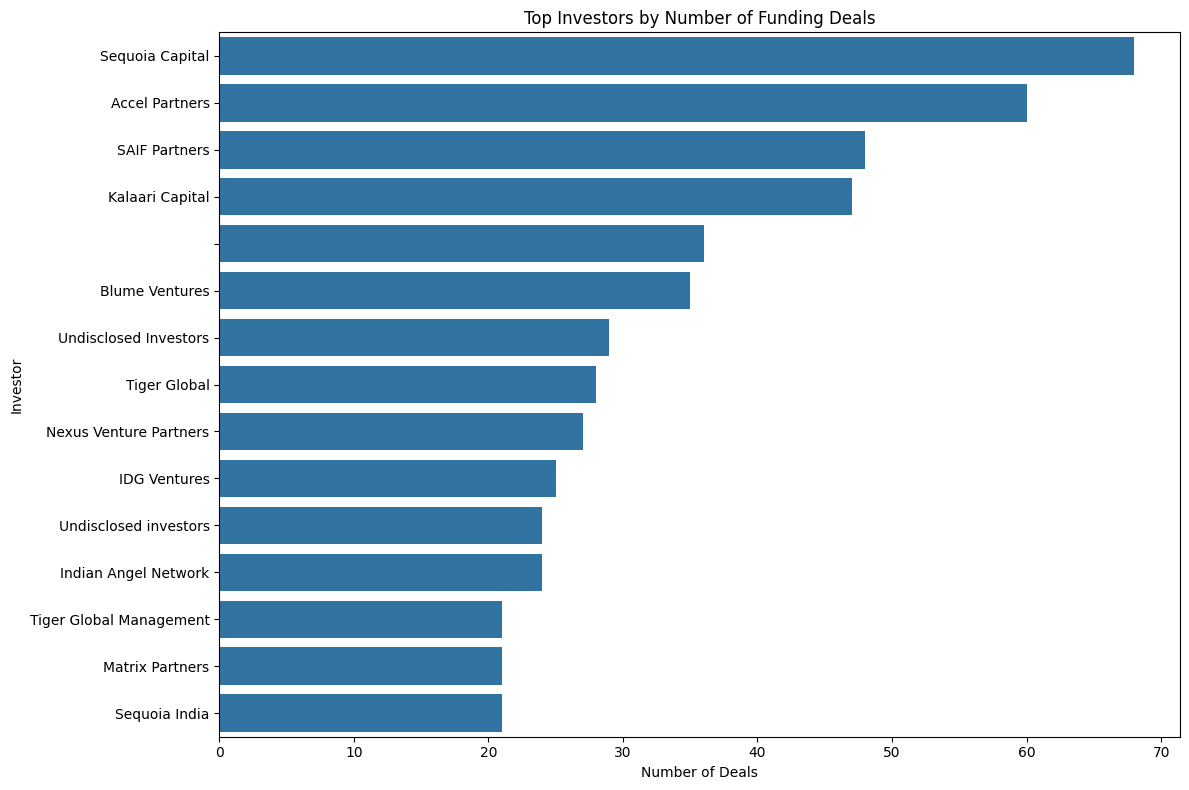

In [ ]:
top_investors = (
    investor_analysis
    .head(15)
    .reset_index()
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_investors,
    x="Deal_Count",
    y="Investors"
)

plt.title("Top Investors by Number of Funding Deals")
plt.xlabel("Number of Deals")
plt.ylabel("Investor")
plt.tight_layout()
plt.show()

# **31. City vs Sector Analysis:**

In [ ]:
city_sector = pd.pivot_table(
    funding_df,
    values="Funding_USD",
    index="City",
    columns="Industry_Vertical",
    aggfunc="sum",
    fill_value=0
)

In [ ]:
top_city_names = city_analysis.head(10).index

top_sector_names = sector_analysis.head(10).index

city_sector_top = city_sector.loc[
    city_sector.index.intersection(top_city_names),
    city_sector.columns.intersection(top_sector_names)
]

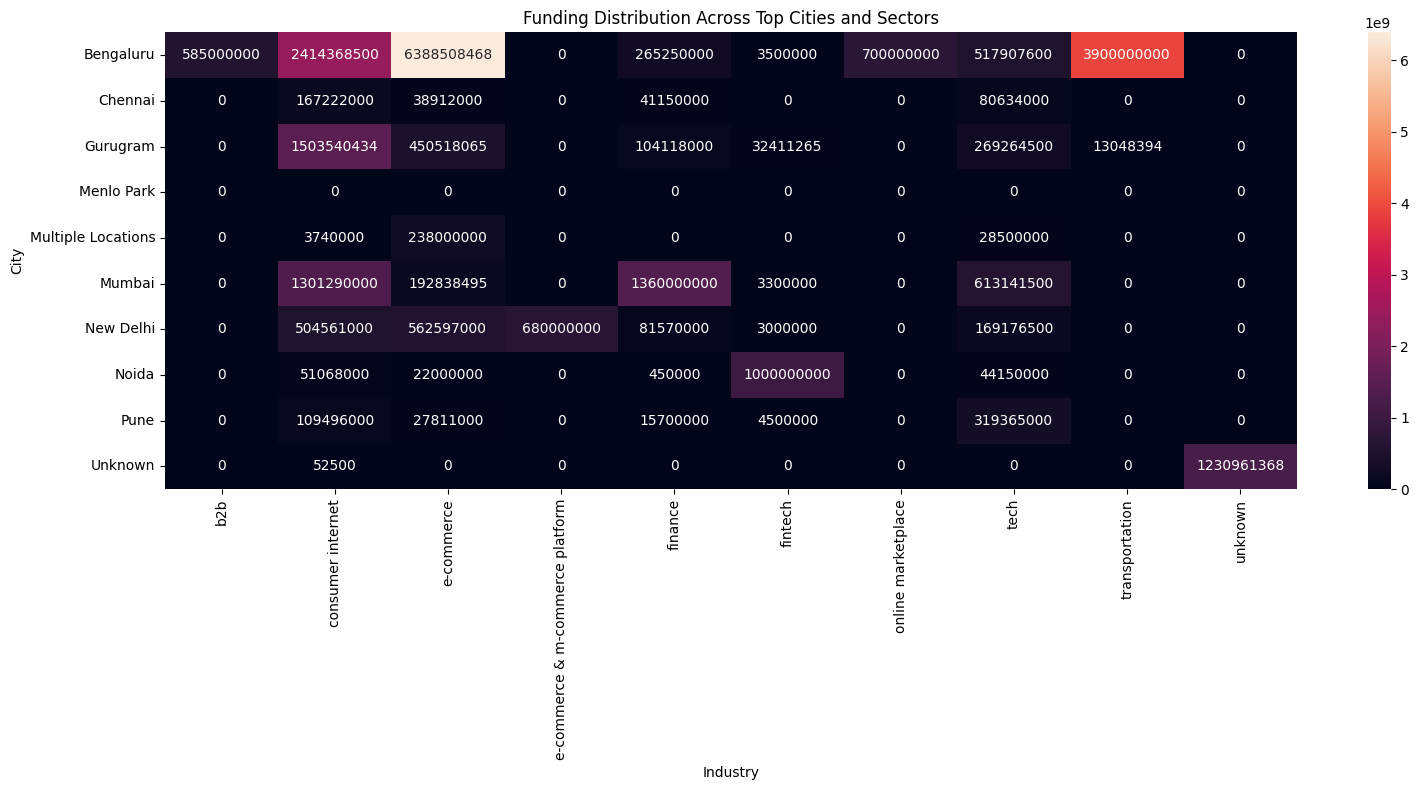

In [ ]:
plt.figure(figsize=(16, 8))

sns.heatmap(
    city_sector_top,
    annot=True,
    fmt=".0f"
)

plt.title("Funding Distribution Across Top Cities and Sectors")
plt.xlabel("Industry")
plt.ylabel("City")
plt.tight_layout()
plt.show()

# **32. Funding Distribution:**

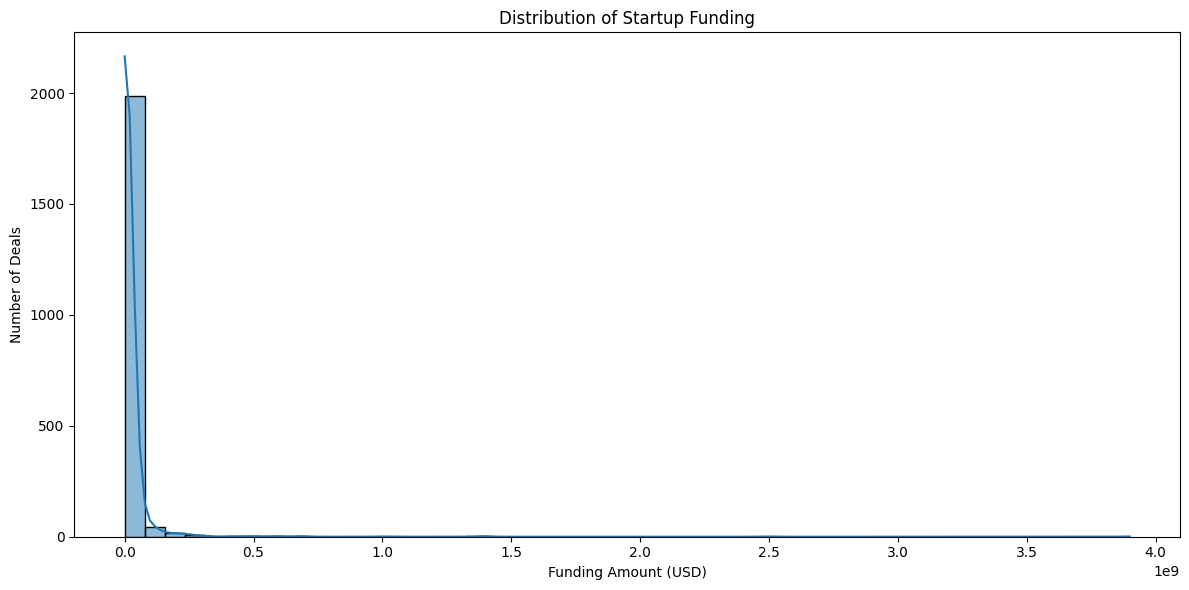

In [ ]:
plt.figure(figsize=(12, 6))

sns.histplot(
    funding_df["Funding_USD"],
    bins=50,
    kde=True
)

plt.title("Distribution of Startup Funding")
plt.xlabel("Funding Amount (USD)")
plt.ylabel("Number of Deals")
plt.tight_layout()
plt.show()

# **33. Log Scale Distribution:**

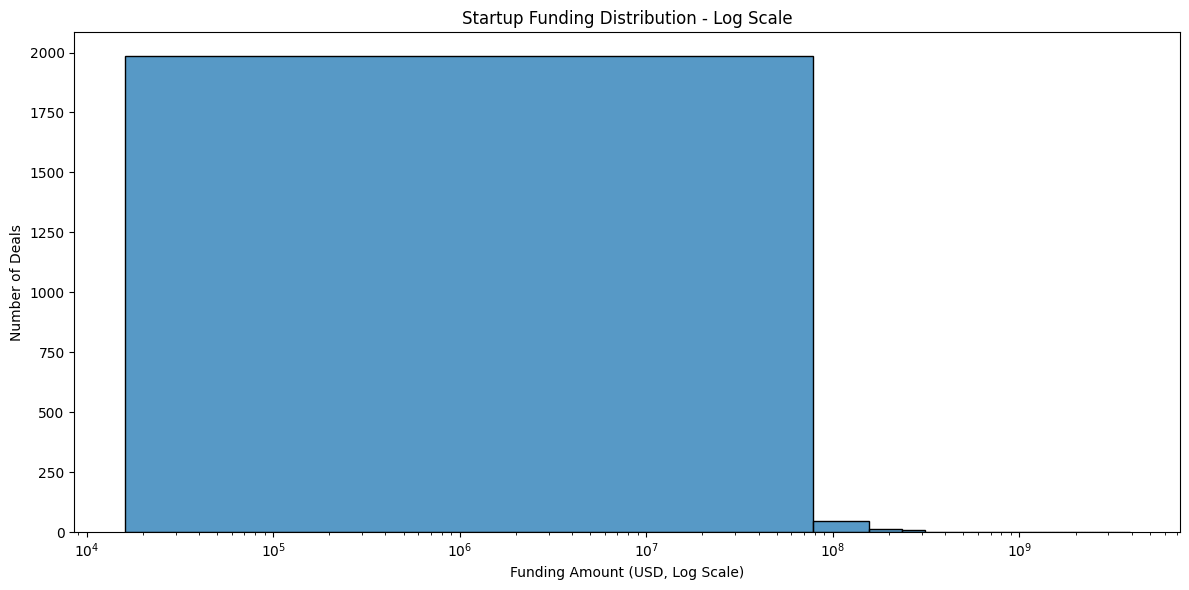

In [ ]:
plt.figure(figsize=(12, 6))

sns.histplot(
    funding_df["Funding_USD"],
    bins=50
)

plt.xscale("log")

plt.title("Startup Funding Distribution - Log Scale")
plt.xlabel("Funding Amount (USD, Log Scale)")
plt.ylabel("Number of Deals")
plt.tight_layout()
plt.show()

# **34. Boxplot and Outliers:**

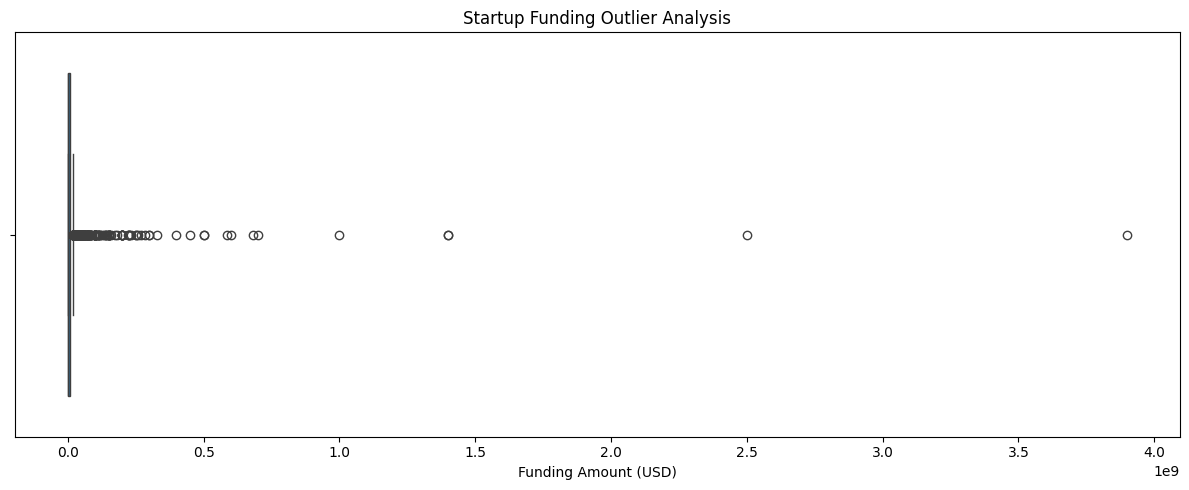

In [ ]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    x=funding_df["Funding_USD"]
)

plt.title("Startup Funding Outlier Analysis")
plt.xlabel("Funding Amount (USD)")
plt.tight_layout()
plt.show()

# **35. IQR Outlier Analysis**

In [ ]:
Q1 = funding_df["Funding_USD"].quantile(0.25)
Q3 = funding_df["Funding_USD"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = funding_df[
    (funding_df["Funding_USD"] < lower_bound) |
    (funding_df["Funding_USD"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))

Q1: 477750.0
Q3: 8036295.5
IQR: 7558545.5
Lower Bound: -10860068.25
Upper Bound: 19374113.75
Number of Outliers: 284


# **36. Top Outlier Deals:**

In [ ]:
outliers[
    [
        "Date",
        "Startup_Name",
        "Industry_Vertical",
        "City",
        "Investment_Type",
        "Funding_USD"
    ]
].sort_values(
    "Funding_USD",
    ascending=False
).head(20)

,Date,Startup_Name,Industry_Vertical,City,Investment_Type,Funding_USD
60,2019-08-27,Rapido Bike Taxi,transportation,Bengaluru,series b,"3,900,000,000.00"
651,2017-08-11,Flipkart,e-commerce,Bengaluru,private equity round,"2,500,000,000.00"
966,2017-03-21,Flipkart,e-commerce,Bengaluru,private equity round,"1,400,000,000.00"
830,2017-05-18,Paytm,e-commerce,Bengaluru,private equity round,"1,400,000,000.00"
31,2019-11-25,Paytm,fintech,Noida,funding round,"1,000,000,000.00"
2648,2015-07-28,Flipkart.com,online marketplace,Bengaluru,private equity round,"700,000,000.00"
2459,2015-09-29,Paytm,e-commerce & m-commerce platform,New Delhi,private equity round,"680,000,000.00"
188,2018-08-30,True North,finance,Mumbai,private equity round,"600,000,000.00"
33,2019-10-02,Udaan,b2b,Bengaluru,series d,"585,000,000.00"
2244,2015-11-18,Ola,car aggregator & retail mobile app,Bengaluru,private equity round,"500,000,000.00"


# **37. Funding Concentration:**

In [ ]:
sorted_funding = funding_df.sort_values(
    "Funding_USD",
    ascending=False
).reset_index(drop=True)

total_funding = sorted_funding["Funding_USD"].sum()

top_10_funding_share = (
    sorted_funding.head(10)["Funding_USD"].sum()
    / total_funding
    * 100
)

top_50_funding_share = (
    sorted_funding.head(50)["Funding_USD"].sum()
    / total_funding
    * 100
)

print(f"Top 10 deals share of total funding: {top_10_funding_share:.2f}%")
print(f"Top 50 deals share of total funding: {top_50_funding_share:.2f}%")

Top 10 deals share of total funding: 34.80%
Top 50 deals share of total funding: 57.34%


# **38. Year-over-Year Growth:**

In [ ]:
yearly_analysis["YoY_Funding_Growth_%"] = (
    yearly_analysis["Total_Funding"]
    .pct_change()
    * 100
)

yearly_analysis

,Year,Total_Funding,Number_of_Deals,Average_Deal,Median_Deal,YoY_Funding_Growth_%
0,2015,"8,669,042,368.00",649,"13,357,538.32","1,500,000.00",NaN
1,2016,"3,828,088,608.00",586,"6,532,574.42","1,000,000.00",-55.84
2,2017,"10,429,309,730.00",456,"22,871,293.27","2,250,000.00",172.44
3,2018,"5,116,118,369.00",264,"19,379,236.25","3,900,000.00",-50.94
4,2019,"9,686,576,535.22",104,"93,140,158.99","12,000,000.00",89.33
5,2020,"390,207,254.00",7,"55,743,893.43","9,000,000.00",-95.97


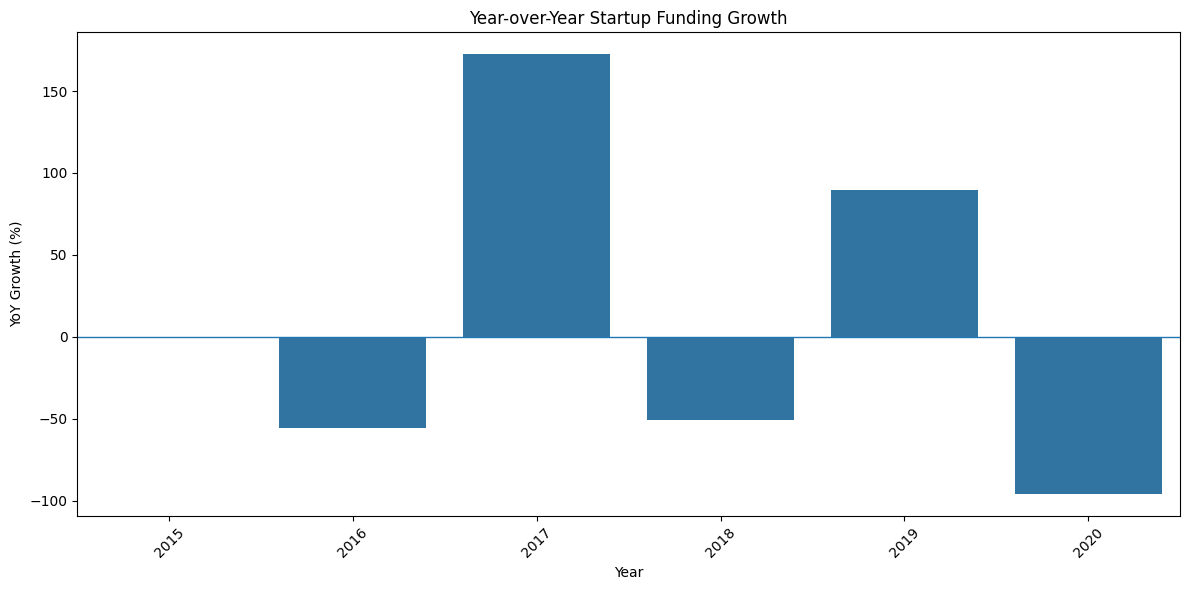

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=yearly_analysis,
    x="Year",
    y="YoY_Funding_Growth_%"
)

plt.axhline(
    0,
    linewidth=1
)

plt.title("Year-over-Year Startup Funding Growth")
plt.xlabel("Year")
plt.ylabel("YoY Growth (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **39. Quarterly Analysis:**

In [ ]:
quarterly_analysis = (
    funding_df
    .groupby(["Year", "Quarter"])
    .agg(
        Total_Funding=("Funding_USD", "sum"),
        Number_of_Deals=("Funding_USD", "count")
    )
    .reset_index()
)

quarterly_analysis

,Year,Quarter,Total_Funding,Number_of_Deals
0,2015,1,"1,226,911,368.00",127
1,2015,2,"1,841,679,000.00",152
2,2015,3,"4,140,363,000.00",195
3,2015,4,"1,460,089,000.00",175
4,2016,1,"1,340,954,608.00",166
5,2016,2,"793,449,000.00",144
6,2016,3,"1,008,997,000.00",140
7,2016,4,"684,688,000.00",136
8,2017,1,"2,812,473,500.00",124
9,2017,2,"2,863,882,000.00",134


# **40. Monthly Funding Trend:**

In [ ]:
monthly_analysis = (
    funding_df
    .groupby("Year_Month")
    .agg(
        Total_Funding=("Funding_USD", "sum"),
        Number_of_Deals=("Funding_USD", "count")
    )
    .reset_index()
)

monthly_analysis.head()

,Year_Month,Total_Funding,Number_of_Deals
0,2015-01,"369,321,768.00",38
1,2015-02,"394,262,600.00",42
2,2015-03,"463,327,000.00",47
3,2015-04,"980,500,000.00",51
4,2015-05,"324,185,000.00",43


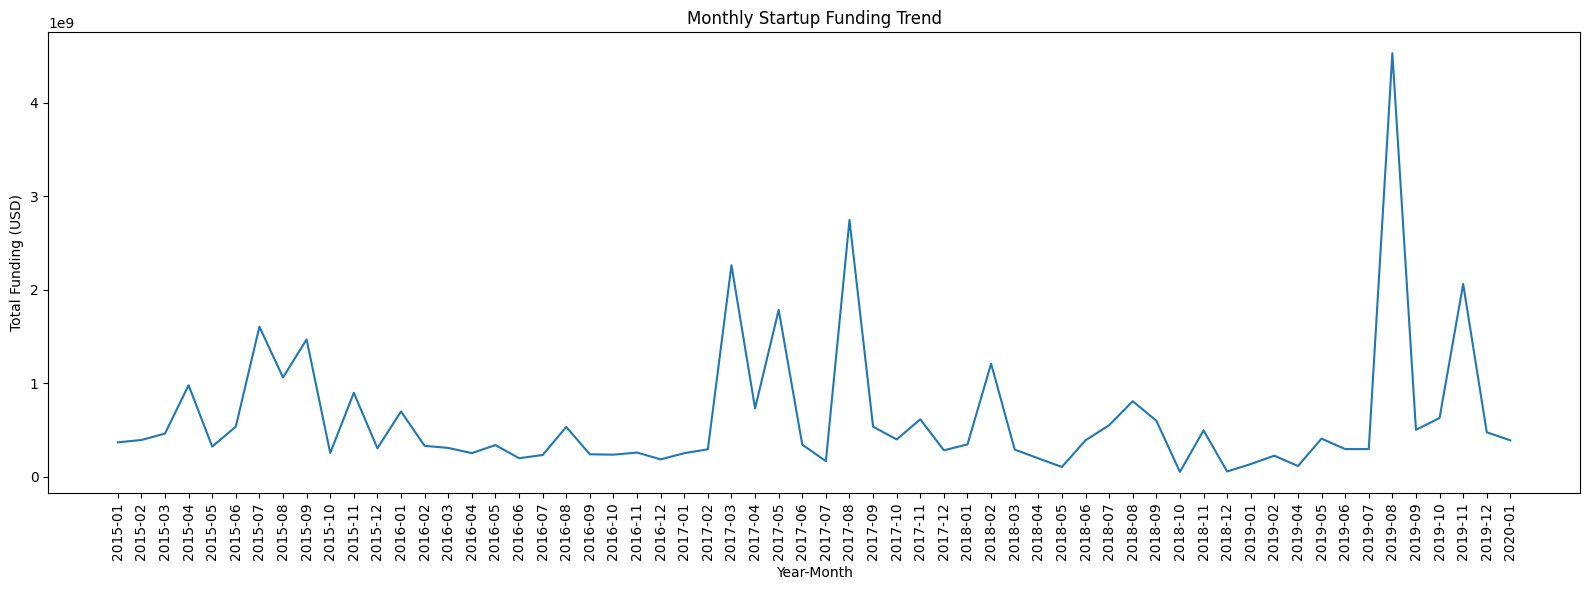

In [ ]:
plt.figure(figsize=(16, 6))

sns.lineplot(
    data=monthly_analysis,
    x="Year_Month",
    y="Total_Funding"
)

plt.title("Monthly Startup Funding Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Funding (USD)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# **41. Funding by Quarter:**

In [ ]:
quarter_summary = (
    funding_df
    .groupby("Quarter")["Funding_USD"]
    .sum()
    .reset_index()
)

quarter_summary

,Quarter,Funding_USD
0,1,"7,984,691,553.00"
1,2,"7,016,364,405.22"
2,3,"15,895,492,416.00"
3,4,"7,222,794,490.00"


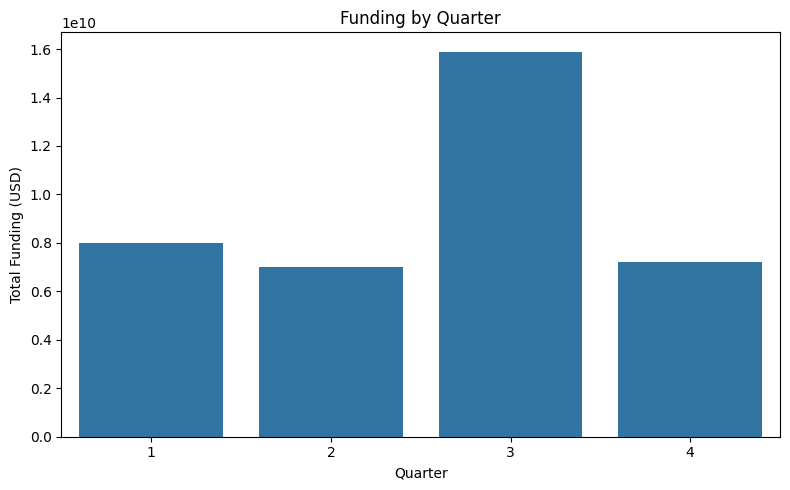

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=quarter_summary,
    x="Quarter",
    y="Funding_USD"
)

plt.title("Funding by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Total Funding (USD)")
plt.tight_layout()
plt.show()

# **42. Negative Funding Check:**

In [ ]:
negative_funding = funding_df[
    funding_df["Funding_USD"] < 0
]

negative_funding

,Sr_No,Date,Startup_Name,Industry_Vertical,Sub_Vertical,City,Investors,Investment_Type,Funding_USD,Remarks,Year,Month,Month_Name,Quarter,Year_Month


# **43. Startup Funding Summary Table:**

In [ ]:
startup_summary = (
    funding_df
    .groupby("Startup_Name")
    .agg(
        Total_Funding=("Funding_USD", "sum"),
        Funding_Rounds=("Funding_USD", "count"),
        First_Funding_Date=("Date", "min"),
        Last_Funding_Date=("Date", "max")
    )
    .sort_values(
        "Total_Funding",
        ascending=False
    )
)

startup_summary.head(20)

,Total_Funding,Funding_Rounds,First_Funding_Date,Last_Funding_Date
Startup_Name,,,,
Flipkart,"4,059,700,000.00",5,2015-06-04,2017-08-11
Rapido Bike Taxi,"3,900,000,000.00",1,2019-08-27,2019-08-27
Paytm,"3,148,950,000.00",5,2015-09-29,2019-11-25
Ola,"984,500,000.00",4,2015-11-18,2017-06-14
Udaan,"870,000,000.00",4,2016-11-23,2019-10-02
Snapdeal,"700,000,000.00",2,2015-08-01,2016-02-15
Flipkart.com,"700,000,000.00",1,2015-07-28,2015-07-28
Ola Cabs,"669,700,000.00",7,2015-09-14,2019-07-03
True North,"600,000,000.00",1,2018-08-30,2018-08-30


# **44. Sector Performance Table:**

In [ ]:
sector_performance = (
    funding_df
    .groupby("Industry_Vertical")
    .agg(
        Total_Funding=("Funding_USD", "sum"),
        Deals=("Funding_USD", "count"),
        Average_Deal=("Funding_USD", "mean"),
        Median_Deal=("Funding_USD", "median"),
        Unique_Startups=("Startup_Name", "nunique")
    )
    .sort_values(
        "Total_Funding",
        ascending=False
    )
)

sector_performance.head(20)

,Total_Funding,Deals,Average_Deal,Median_Deal,Unique_Startups
Industry_Vertical,,,,,
e-commerce,"8,246,393,692.54",204,"40,423,498.49","3,000,000.00",170
consumer internet,"6,247,834,245.00",589,"10,607,528.43","1,000,000.00",522
transportation,"3,916,632,394.00",4,"979,158,098.50","6,524,197.00",3
tech,"2,251,457,930.00",312,"7,216,211.31","1,500,000.00",300
finance,"1,971,438,000.00",57,"34,586,631.58","6,240,000.00",53
unknown,"1,230,961,368.00",129,"9,542,336.19","1,500,000.00",127
fintech,"1,224,211,265.00",10,"122,421,126.50","15,250,000.00",10
online marketplace,"700,143,000.00",2,"350,071,500.00","350,071,500.00",2
e-commerce & m-commerce platform,"680,000,000.00",1,"680,000,000.00","680,000,000.00",1


# **45. City Performance Table**

In [ ]:
city_performance = (
    funding_df
    .groupby("City")
    .agg(
        Total_Funding=("Funding_USD", "sum"),
        Deals=("Funding_USD", "count"),
        Average_Deal=("Funding_USD", "mean"),
        Unique_Startups=("Startup_Name", "nunique")
    )
    .sort_values(
        "Total_Funding",
        ascending=False
    )
)

city_performance.head(20)

,Total_Funding,Deals,Average_Deal,Unique_Startups
City,,,,
Bengaluru,"18,476,366,863.00",583,"31,691,881.41",462
Mumbai,"4,931,155,015.00",398,"12,389,836.72",347
Gurugram,"3,876,913,657.54",243,"15,954,377.19",187
New Delhi,"3,302,171,515.00",268,"12,321,535.50",238
Noida,"1,282,864,000.00",56,"22,908,285.71",51
Unknown,"1,271,013,868.00",133,"9,556,495.25",131
Chennai,"718,767,000.00",75,"9,583,560.00",69
Pune,"633,082,000.00",71,"8,916,647.89",65
Multiple Locations,"544,590,000.00",32,"17,018,437.50",29


# **46. Correlation:**

In [ ]:
numeric_df = funding_df[
    [
        "Year",
        "Quarter",
        "Month",
        "Funding_USD"
    ]
]

numeric_df.corr()

,Year,Quarter,Month,Funding_USD
Year,1.00,-0.09,-0.10,0.10
Quarter,-0.09,1.00,0.97,0.02
Month,-0.10,0.97,1.00,0.02
Funding_USD,0.10,0.02,0.02,1.00


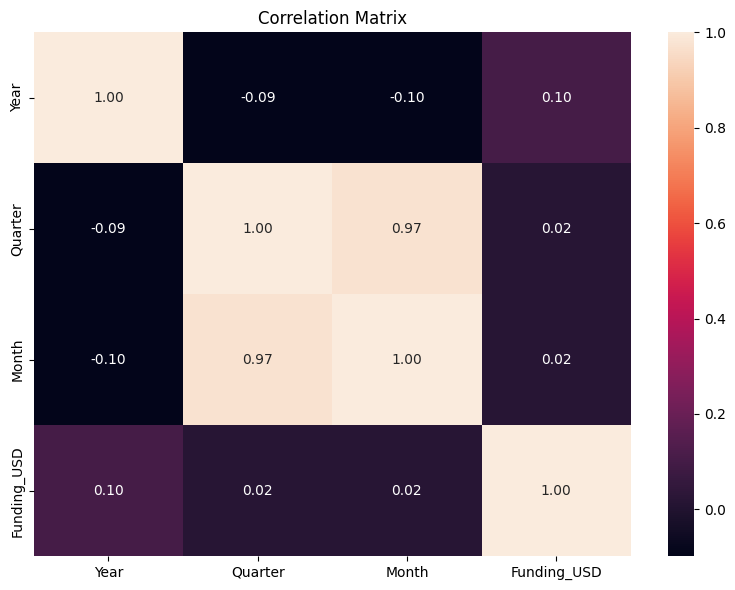

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

# **47. Final Data Export**

In [ ]:
final_df = df.copy()

final_df.to_csv(
    "Indian_Startup_Funding_Cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully.")

Cleaned dataset exported successfully.


# **48. Analysis Tables Export**

In [ ]:
sector_performance.to_csv(
    "sector_analysis.csv"
)

city_performance.to_csv(
    "city_analysis.csv"
)

startup_summary.to_csv(
    "startup_analysis.csv"
)

yearly_analysis.to_csv(
    "yearly_funding_analysis.csv"
)

investment_analysis.to_csv(
    "investment_type_analysis.csv"

)

print("Analysis files exported successfully.")

Analysis files exported successfully.


# **Key Insights:**

## **`1. Funding Concentration`**

The funding data shows that startup investment is concentrated among a
relatively small number of large funding deals.

## **`2. Sector Concentration`**

A few major industries account for a significant share of total startup funding.

## **`3. Geographic Concentration`**

Startup funding is concentrated in major startup hubs, while smaller cities
receive comparatively lower funding activity.

## **`4. Funding Stage`**

Different investment types show significant differences in both deal volume
and average funding size.

## **`5. Deal Size`**

The difference between average and median funding indicates that large funding
rounds can significantly influence overall funding totals.

## **`6. Funding Trend`**

Year-wise analysis helps identify periods of increasing or decreasing startup
funding activity.

## **`7. Investor Activity`**

Investor participation is concentrated among a smaller group of frequently
appearing investors.

# **Business Recommendations**

### 1. Focus on High-Funding Sectors

Investors can use sector-level funding trends to identify industries with
strong capital activity.

### 2. Analyze Deal Size Separately from Deal Volume

A sector with fewer deals may still attract significant capital if its average
deal size is high.

### 3. Monitor Emerging Cities

While major startup hubs dominate funding, smaller cities can be evaluated
for emerging opportunities and diversification.

### 4. Evaluate Investment Types

Investors can compare investment stages based on total funding, number of deals,
and average deal size.

### 5. Track Funding Concentration

Large funding rounds can significantly influence total funding. Therefore,
funding concentration should be considered when interpreting market trends.

# **Final Conclusion**

This project provides an end-to-end analysis of Indian startup funding activity.

The analysis covers data cleaning, exploratory analysis, KPI development,
funding trends, sector performance, city-level funding, investment types,
startup-level funding, investor activity, outlier detection, and funding
concentration.

The project demonstrates how raw startup funding data can be transformed into
structured business insights using Python and data analytics techniques.

The findings can help investors, founders, and analysts understand funding
patterns, identify highly funded sectors and cities, and evaluate changes in
startup investment activity over time.